# Customer Intent Classification for AI-Powered Support

Open-source public dataset data science project for Reylo AI.

Issue: Can simple, interpretable NLP models classify customer support messages into common intents?

Dataset: using public customer support public data Bitext from HuggingFace (https://huggingface.co/datasets/bitext/Bitext-customer-support-llm-chatbot-training-dataset)

Notebook outline: (1) setup and data source -> (2) exploration -> (3) train/validation/test split -> (4) model comparison -> (5) held-out evaluation -> (6) error analysis -> (7) testing with custom input -> (8) business insights and action plan.


## Approach and thought process

- I want to start with the simplest method TF-IDF with linear model (fast, interpretable, and a sensible baseline before trying embeddings or LLMs).
- I will use the 6 existing labels in the datase to test whether routing signals are learnable (complaint, contact_human_agent, payment_issue, get_refund, cancel_order, check_payment_methods)
- Preprocessing & tuning: I will do basic feature engineering e.g. deduplicate before splitting, tune on validation only, and touch the test set once.
- Evaluation: Using F1 metrics. Each intent matters, so a strong score on frequent classes should not hide a weak one. I will also inspect mistakes, not just the score. Errors can show which messages are too vague or too costly to route automatically. I will also treat probabilities as signals, not facts. Model scores need calibration before they drive any threshold.


## 1. Setup and data source

This project is inspired by the Bitext Customer Support dataset on Hugging Face. It may be similar to what Euromedika needs: real-style customer messages paired with intent labels.

The dataset contains instruction (message), intent (label), response (example assistant answer), category, and flags. 

In [1]:
from pathlib import Path
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from datasets import load_dataset
from IPython.display import display
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay, accuracy_score, classification_report,
    confusion_matrix, f1_score,
)
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline

SEED = 42
FIGURES = Path("figures")
FIGURES.mkdir(exist_ok=True)
DATASET_NAME = "bitext/Bitext-customer-support-llm-chatbot-training-dataset"
SELECTED_INTENTS = [
    "complaint", "contact_human_agent", "payment_issue",
    "get_refund", "cancel_order", "check_payment_methods",
]
sns.set_theme(style="whitegrid")

try:
    dataset = load_dataset(DATASET_NAME)
    raw = dataset["train"].to_pandas()
except Exception as exc:
    raise RuntimeError(
        "Unable to load the Bitext dataset from Hugging Face. Check your "
        "connection and the dataset name."
    ) from exc

required = {"instruction", "intent"}
if not required.issubset(raw.columns):
    raise ValueError(f"Missing required columns: {required - set(raw.columns)}")
print(dataset)
print("Source rows:", len(raw))
print("Columns:", list(raw.columns))
print("Selected intents available:", sorted(set(raw["intent"].dropna()) & set(SELECTED_INTENTS)))

DatasetDict({
    train: Dataset({
        features: ['flags', 'instruction', 'category', 'intent', 'response'],
        num_rows: 26872
    })
})
Source rows: 26872
Columns: ['flags', 'instruction', 'category', 'intent', 'response']
Selected intents available: ['cancel_order', 'check_payment_methods', 'complaint', 'contact_human_agent', 'get_refund', 'payment_issue']


## 2. Exploratory data analysis (EDA)

Filter to the six labels, check missing values and class balance, and look at sample messages before modeling.


Rows before cleaning: 5992
Missing values:
 instruction    0
intent         0
dtype: int64


,count
intent,
complaint,1000
contact_human_agent,999
payment_issue,999
get_refund,997
cancel_order,998
check_payment_methods,999


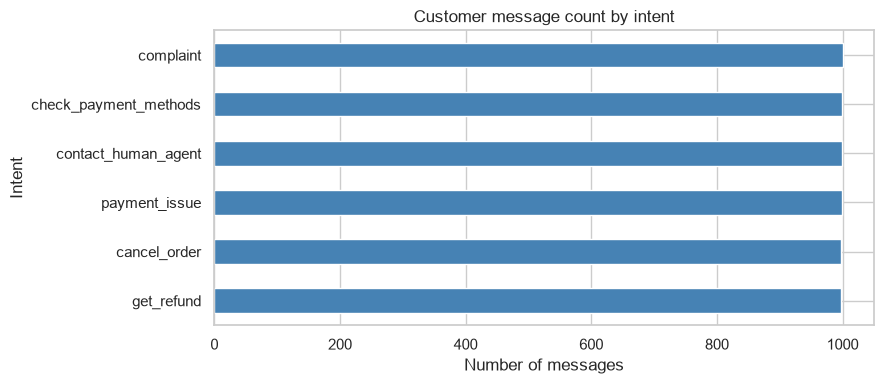


Sample messages per intent:


,instruction,intent
0,I cannot afford purchase {{Order Number}},cancel_order
1,"I have bought some item, I have to cancel orde...",cancel_order
2,how do I list the allowed payment methods?,check_payment_methods
3,how to list ur allowed payment modalities,check_payment_methods
4,help me to lodge a reclamation against your co...,complaint
5,i want help filing a damn customer claim again...,complaint
6,I do not know what to do to chat with an operator,contact_human_agent
7,how can I talk to somebody?,contact_human_agent
8,need assistance getting refunds of moey,get_refund
9,I want help to ask for a reimbursement of my m...,get_refund


In [2]:
df = raw.loc[raw["intent"].isin(SELECTED_INTENTS), ["instruction", "intent"]].copy()
print("Rows before cleaning:", len(df))
print("Missing values:\n", df.isna().sum())
df = df.dropna(subset=["instruction", "intent"])
df["instruction"] = df["instruction"].astype(str)
df = df.loc[df["instruction"].str.strip().ne("")].copy()

missing_intents = set(SELECTED_INTENTS) - set(df["intent"].unique())
if missing_intents:
    raise ValueError(f"No examples found for selected intent(s): {missing_intents}")

counts = df["intent"].value_counts().reindex(SELECTED_INTENTS)
display(counts.rename("count").to_frame())
ax = counts.sort_values().plot.barh(figsize=(9, 4), color="steelblue")
ax.set(title="Customer message count by intent", xlabel="Number of messages", ylabel="Intent")
plt.tight_layout()
plt.savefig(FIGURES / "intent_distribution.png", dpi=160, bbox_inches="tight")
plt.show()

print("\nSample messages per intent:")
display(df.groupby("intent", group_keys=False).sample(n=2, random_state=SEED).reset_index(drop=True))

### Duplicate and conflicting-text checks

The same text with different labels is ambiguous, so those rows are excluded. Deduplication happens before the split to prevent identical messages from appearing in both training and evaluation. Near-duplicate templates can still inflate scores and are noted as a limitation.


In [3]:
def normalize_for_dedup(text: str) -> str:
    return re.sub(r"\s+", " ", text.strip().casefold())

df["normalized_text"] = df["instruction"].map(normalize_for_dedup)
conflict_counts = df.groupby("normalized_text")["intent"].nunique()
conflicting_texts = set(conflict_counts[conflict_counts > 1].index)
print("Duplicate normalized messages:", df.duplicated("normalized_text").sum())
print("Texts appearing under multiple labels:", len(conflicting_texts))

df = df.loc[~df["normalized_text"].isin(conflicting_texts)]
df = df.drop_duplicates("normalized_text", keep="first").reset_index(drop=True)
print("Final labeled unique messages:", len(df))
display(df["intent"].value_counts().rename("count").to_frame())
if df["intent"].value_counts().min() < 10:
    raise ValueError("Too few examples in at least one class for meaningful splitting.")

Duplicate normalized messages: 683
Texts appearing under multiple labels: 0
Final labeled unique messages: 5309


,count
intent,
complaint,997
check_payment_methods,993
payment_issue,993
contact_human_agent,979
get_refund,911
cancel_order,436


## 3. Stratified train/validation/test split

Using a 70% / 15% / 15% stratified split. The vectorizer and model are fitted on training data only, and the test set is not used for model selection.


In [4]:
X = df["instruction"]
y = df["intent"]
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=SEED
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=SEED
)
print(f"Train: {len(X_train)}, validation: {len(X_val)}, test: {len(X_test)}")
assert not (set(X_train.map(normalize_for_dedup)) & set(X_val.map(normalize_for_dedup)))
assert not (set(X_train.map(normalize_for_dedup)) & set(X_test.map(normalize_for_dedup)))
assert not (set(X_val.map(normalize_for_dedup)) & set(X_test.map(normalize_for_dedup)))

Train: 3716, validation: 796, test: 797


## 4. Baseline and candidate models

The dummy baseline predicts the most frequent class. Then, the model candidates are TF-IDF + Multinomial Naive Bayes and TF-IDF + Logistic Regression. Wrapping each in a Pipeline keeps TF-IDF statistics inside the training fold.


In [5]:
models = {
    "Dummy (most frequent)": DummyClassifier(strategy="most_frequent"),
    "TF-IDF + Naive Bayes": Pipeline([
        ("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_features=25000)),
        ("clf", MultinomialNB()),
    ]),
    "TF-IDF + Logistic Regression": Pipeline([
        ("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_features=25000)),
        ("clf", LogisticRegression(max_iter=1000, random_state=SEED)),
    ]),
}

rows = []
for name, model in models.items():
    model.fit(X_train, y_train)
    predictions = model.predict(X_val)
    rows.append({
        "model": name,
        "val_accuracy": accuracy_score(y_val, predictions),
        "val_macro_f1": f1_score(y_val, predictions, average="macro", zero_division=0),
    })
validation_results = pd.DataFrame(rows).sort_values("val_macro_f1", ascending=False)
display(validation_results.round(4))

# Exclude dummy baseline from final candidate selection.
candidates = validation_results.loc[validation_results["model"] != "Dummy (most frequent)"]
best_name = candidates.iloc[0]["model"]
best_model = models[best_name]
print("Selected based on validation macro-F1:", best_name)

,model,val_accuracy,val_macro_f1
1,TF-IDF + Naive Bayes,0.9987,0.9989
2,TF-IDF + Logistic Regression,0.9987,0.9989
0,Dummy (most frequent),0.1872,0.0526


Selected based on validation macro-F1: TF-IDF + Naive Bayes


## 5. Final held-out evaluation

The test set is scored once after model selection. Macro-F1 is the primary metric because each class matters equally, accuracy and per-class precision/recall add context.


Selected model: TF-IDF + Naive Bayes
Test accuracy: 0.9962
Test macro-F1: 0.9959

Classification report:
                       precision    recall  f1-score   support

            complaint       0.99      1.00      1.00       150
  contact_human_agent       1.00      0.99      1.00       147
        payment_issue       1.00      0.99      0.99       149
           get_refund       1.00      1.00      1.00       137
         cancel_order       0.98      1.00      0.99        65
check_payment_methods       0.99      1.00      1.00       149

             accuracy                           1.00       797
            macro avg       1.00      1.00      1.00       797
         weighted avg       1.00      1.00      1.00       797



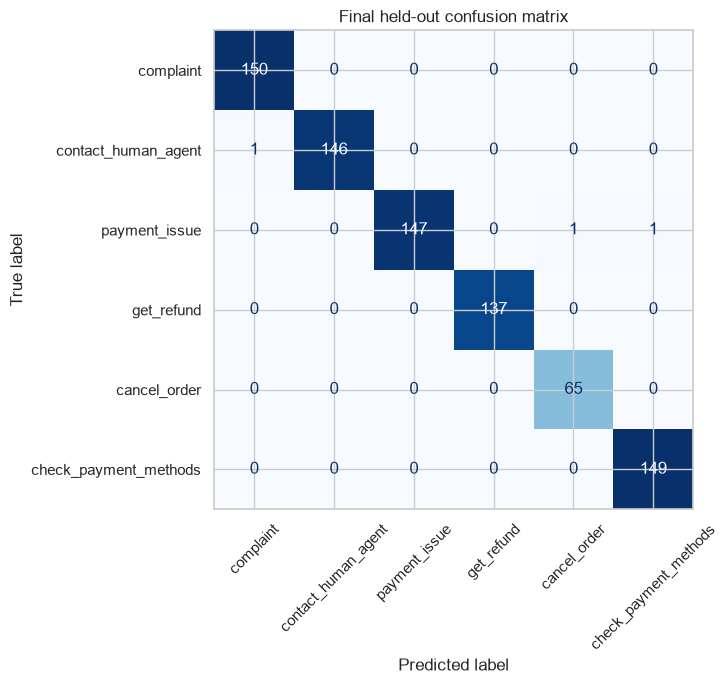

In [6]:
test_predictions = best_model.predict(X_test)
test_accuracy = accuracy_score(y_test, test_predictions)
test_macro_f1 = f1_score(y_test, test_predictions, average="macro", zero_division=0)
print(f"Selected model: {best_name}")
print(f"Test accuracy: {test_accuracy:.4f}")
print(f"Test macro-F1: {test_macro_f1:.4f}")
print("\nClassification report:")
print(classification_report(y_test, test_predictions, labels=SELECTED_INTENTS, zero_division=0))

cm = confusion_matrix(y_test, test_predictions, labels=SELECTED_INTENTS)
fig, ax = plt.subplots(figsize=(9, 7))
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=SELECTED_INTENTS).plot(
    ax=ax, cmap="Blues", xticks_rotation=45, colorbar=False, values_format="d"
)
ax.set_title("Final held-out confusion matrix")
plt.tight_layout()
plt.savefig(FIGURES / "confusion_matrix.png", dpi=160, bbox_inches="tight")
plt.show()

## 6. Error analysis

A single score does not show whether mistakes are costly. Review the misclassified messages, especially complaints, requests for a human, and payment issues.


In [7]:
errors = pd.DataFrame({
    "message": X_test.to_numpy(),
    "actual_intent": y_test.to_numpy(),
    "predicted_intent": test_predictions,
})
errors = errors.loc[errors["actual_intent"] != errors["predicted_intent"]]
print(f"Errors: {len(errors)} of {len(X_test)} test examples")
if not errors.empty:
    print("Most common intent confusions:")
    display(errors.groupby(["actual_intent", "predicted_intent"]).size()
            .sort_values(ascending=False).head(10).rename("count").to_frame())
    print("Example misclassifications (review qualitative causes):")
    display(errors.sample(n=min(12, len(errors)), random_state=SEED).reset_index(drop=True))
else:
    print("No errors in held-out set. This is not proof of production readiness: the source is synthetic.")

Errors: 3 of 797 test examples
Most common intent confusions:


count
actual_intent       predicted_intent            
contact_human_agent complaint                  1
payment_issue       cancel_order               1
                    check_payment_methods      1

Example misclassifications (review qualitative causes):


,message,actual_intent,predicted_intent
0,payment help,payment_issue,check_payment_methods
1,i have an question about the payment,payment_issue,cancel_order
2,contactingassistant,contact_human_agent,complaint


## 7. Testing with custom input

These written messages check the prediction API on realistic phrasing, including one message outside the six supported intents. The model must still return one of its known classes, so out-of-scope and low-confidence messages need separate handling.

The maximum class probability is shown for exploration only. It is not calibrated and should not be used as an approved routing threshold without further work.


In [8]:
sample_messages = [
    "I want to talk to a real person, please.",
    "My card keeps getting declined when I try to pay.",
    "What payment methods do you accept?",
    "I'd like to request a refund for my order.",
    "Please cancel my order.",
    "I want to file a complaint about the service.",
    "Can I book a facial appointment for Saturday?",  # Out of scope: no booking class
]
probs = best_model.predict_proba(sample_messages)
classes = best_model.classes_
output = pd.DataFrame({
    "message": sample_messages,
    "predicted_intent": best_model.predict(sample_messages),
    "max_model_probability_uncalibrated": np.max(probs, axis=1).round(3),
})
display(output)

,message,predicted_intent,max_model_probability_uncalibrated
0,"I want to talk to a real person, please.",contact_human_agent,0.986
1,My card keeps getting declined when I try to pay.,payment_issue,0.365
2,What payment methods do you accept?,check_payment_methods,0.994
3,I'd like to request a refund for my order.,get_refund,0.959
4,Please cancel my order.,cancel_order,0.889
5,I want to file a complaint about the service.,complaint,0.936
6,Can I book a facial appointment for Saturday?,get_refund,0.741


## 8. Business insights and action plan

### Business insights

- Intent prediction is best used as a routing suggestion, with a human confirming sensitive or ambiguous cases.
- Complaints and requests for a human agent should be escalated rather than auto-answered.
- Payment, refund, and cancellation messages are common enough to justify dedicated queues or templates.
- The near-perfect test score comes from synthetic, template-like data. It is evidence that the method works, not a production forecast.
- Short, vague messages are the main failure mode. Message length, confidence, and missing context are useful review triggers.

### Action plan

1. For real clinical data: Collect permitted, de-identified real messages and define a clinic-specific taxonomy (booking, appointment changes, pricing, billing, complaint, symptom concern).
2. Build a held-out evaluation set with clear annotation rules and measure per-class quality plus out-of-scope detection.
3. Calibrate probabilities or add a separate out-of-scope model before using any confidence threshold.
4. Run a human-in-the-loop pilot (check manually) and track routing accuracy, escalation rate, first-response time, and customer satisfaction.
5. Monitor language and intent drift, and retrain on reviewed examples.

I hope this project gives a clear picture of my approach to data science and how I could apply it to support Reylo's needs. Thank you for the opportunity, and I look forward to our discussion!
